# Continuous XNOR — results and prediction analysis

This notebook only reads saved CSVs; it never trains a model. Run Notebooks 01 and 02 first, or use their existing results. Choose preview or research results explicitly below. All shading is one sample standard deviation across initialization seeds, not a confidence interval.

In [1]:
%matplotlib inline
from pathlib import Path
import sys
import json
import inspect
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from IPython.display import display, clear_output, Code

# Launch Jupyter here, or open these notebooks from the project root.
HERE = Path.cwd()
if not (HERE / 'notebook_experiment.py').exists():
    HERE = HERE / 'continuous_xnor'
assert (HERE / 'notebook_experiment.py').exists(), 'Launch Jupyter from the continuous_xnor folder.'
sys.path.insert(0, str(HERE))
from notebook_experiment import *
torch.set_num_threads(1)
RESULTS = HERE / 'results'
print('PyTorch:', torch.__version__)


PyTorch: 2.14.1+cpu


In [2]:
READ_PREVIEW = False
if READ_PREVIEW:
    RESULTS = RESULTS / 'preview'
final = pd.read_csv(RESULTS / 'final_summary.csv')
history = pd.read_csv(RESULTS / 'training_history.csv')
metadata = json.loads((RESULTS / 'metadata.json').read_text())
conditions = ['ordinary', 'inverse_init', 'compensated_sgd']
assert not final.duplicated(['condition', 'seed', 'alpha']).any()
expected = len(metadata['seeds']) * len(metadata['alphas']) * len(conditions)
assert len(final) == expected, 'The sweep is incomplete. Finish Notebook 02 first.'
expected_keys = {(c, s, a) for c in conditions for s in metadata['seeds'] for a in metadata['alphas']}
assert set(zip(final.condition, final.seed, final.alpha)) == expected_keys
print('Joint runs:', len(final), '| history rows:', len(history), '| output:', RESULTS)
print('Steps:', metadata['steps'], '| seeds:', metadata['seeds'])
if (RESULTS / 'baseline_summary.csv').exists():
    baseline = pd.read_csv(RESULTS / 'baseline_summary.csv')
    baseline_settings = json.loads((RESULTS / 'baseline_settings.json').read_text())
    assert baseline_settings['steps'] == metadata['steps'], 'Baseline and joint budgets differ.'
    assert baseline_settings['lr'] == metadata['lr'], 'Baseline and joint learning rates differ.'
    assert set(baseline_settings['seeds']) == set(metadata['seeds']), 'Baseline and joint seeds differ.'
    display(baseline.groupby('condition')[['test_accuracy', 'test_loss']].agg(['mean', 'std']))
else:
    print('Feature-only baseline results are missing. Run Notebook 01 before drawing conclusions.')


Joint runs: 90 | history rows: 1890 | output: c:\Users\ESHAAN\HAKUR\SimpBias\continuous_xnor\results
Steps: 500 | seeds: [42, 43, 44, 45, 46]


test_accuracy      test_loss          
                      mean  std      mean       std
condition                                          
complex_only           1.0  0.0  0.089268  0.010610
simple_only            1.0  0.0  0.015058  0.000582

## Shared plotting helper

The fixed magnitude distribution is part of the dataset. The horizontal axis is the intentionally manipulated complex scale alpha. The same seed contributes to each scale and condition, so compare changes within seeds as well as the aggregate curves.

In [3]:
labels = {'ordinary': 'Ordinary scaling', 'inverse_init': 'Inverse initialization',
          'compensated_sgd': 'Compensated SGD'}
colors = {'ordinary': 'tab:blue', 'inverse_init': 'tab:orange', 'compensated_sgd': 'tab:green'}
FIGURES = RESULTS / 'figures'
FIGURES.mkdir(exist_ok=True)

def plot_metric(ax, metric, title, bounded=True):
    for condition in conditions:
        group = final[final.condition == condition].groupby('alpha')[metric].agg(['mean', 'std'])
        x, mean = group.index.to_numpy(), group['mean'].to_numpy()
        sd = group['std'].fillna(0).to_numpy()
        lower, upper = mean - sd, mean + sd
        if bounded:
            lower, upper = lower.clip(0, 1), upper.clip(0, 1)
        ax.plot(x, mean, 'o-', label=labels[condition], color=colors[condition])
        ax.fill_between(x, lower, upper, color=colors[condition], alpha=0.15)
    scales = sorted(final.alpha.unique())
    ax.set_xscale('log')
    ax.set_xticks(scales, labels=[f'{a:g}' for a in scales])
    ax.set(title=title, xlabel='Complex scale alpha')
    if bounded:
        ax.set_ylim(-0.05, 1.05)
    ax.grid(alpha=0.2)
    ax.legend(fontsize=8)


## Conflict preference and held-out classification

Conflict agreement asks which rule predictions follow when the rules disagree. Test accuracy and BCE measure performance on new coordinates where both rules agree. High held-out accuracy therefore does not, by itself, establish complex preference.

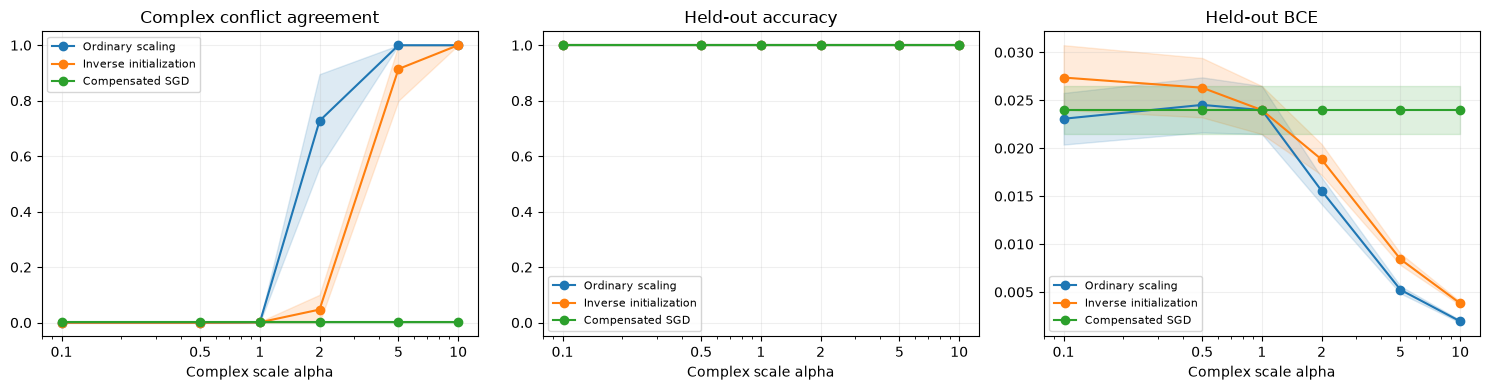

test_accuracy      test_loss            \
                               mean  std      mean       std   
condition       alpha                                          
compensated_sgd 0.1             1.0  0.0  0.023972  0.002510   
                0.5             1.0  0.0  0.023972  0.002510   
                1.0             1.0  0.0  0.023972  0.002510   
                2.0             1.0  0.0  0.023972  0.002510   
                5.0             1.0  0.0  0.023972  0.002510   
                10.0            1.0  0.0  0.023972  0.002510   
inverse_init    0.1             1.0  0.0  0.027363  0.003374   
                0.5             1.0  0.0  0.026305  0.003097   
                1.0             1.0  0.0  0.023972  0.002510   
                2.0             1.0  0.0  0.018827  0.001610   
                5.0             1.0  0.0  0.008416  0.000604   
                10.0            1.0  0.0  0.003817  0.000186   
ordinary        0.1             1.0  0.0  0.023066  0.002692   
                0.5             1.0  0.0  0.024512  0.002869   
                1.0             1.0  0.0  0.023972  0.002510   
                2.0             1.0  0.0  0.015562  0.001396   
                5.0             1.0  0.0  0.005230  0.000381   
                10.0            1.0  0.0  0.001943  0.000137   

                      complex_conflict_agreement            
                                            mean       std  
condition       alpha                                       
compensated_sgd 0.1                     0.001074  0.002402  
                0.5                     0.001074  0.002402  
                1.0                     0.001074  0.002402  
                2.0                     0.001074  0.002402  
                5.0                     0.001074  0.002402  
                10.0                    0.001074  0.002402  
inverse_init    0.1                     0.000000  0.000000  
                0.5                     0.000000  0.000000  
                1.0                     0.001074  0.002402  
                2.0                     0.047070  0.053212  
                5.0                     0.914258  0.114080  
                10.0                    1.000000  0.000000  
ordinary        0.1                     0.000000  0.000000  
                0.5                     0.000000  0.000000  
                1.0                     0.001074  0.002402  
                2.0                     0.727344  0.168215  
                5.0                     1.000000  0.000000  
                10.0                    1.000000  0.000000

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
plot_metric(axes[0], 'complex_conflict_agreement', 'Complex conflict agreement')
plot_metric(axes[1], 'test_accuracy', 'Held-out accuracy')
plot_metric(axes[2], 'test_loss', 'Held-out BCE', bounded=False)
fig.tight_layout()
fig.savefig(FIGURES / 'final_results.png', dpi=170)
plt.show()
display(final.groupby(['condition', 'alpha'])[['test_accuracy', 'test_loss', 'complex_conflict_agreement']].agg(['mean', 'std']))


## Held-out counterfactual sensitivity

Negating the simple coordinate reverses its implied class. Negating one complex coordinate reverses XNOR. Hard flip rates count class changes; mean absolute probability changes also detect smaller confidence movements. These inputs are outside the joint training support. The intervention metrics and conflict scores are related behavioral probes, not independent evidence of internal representations.

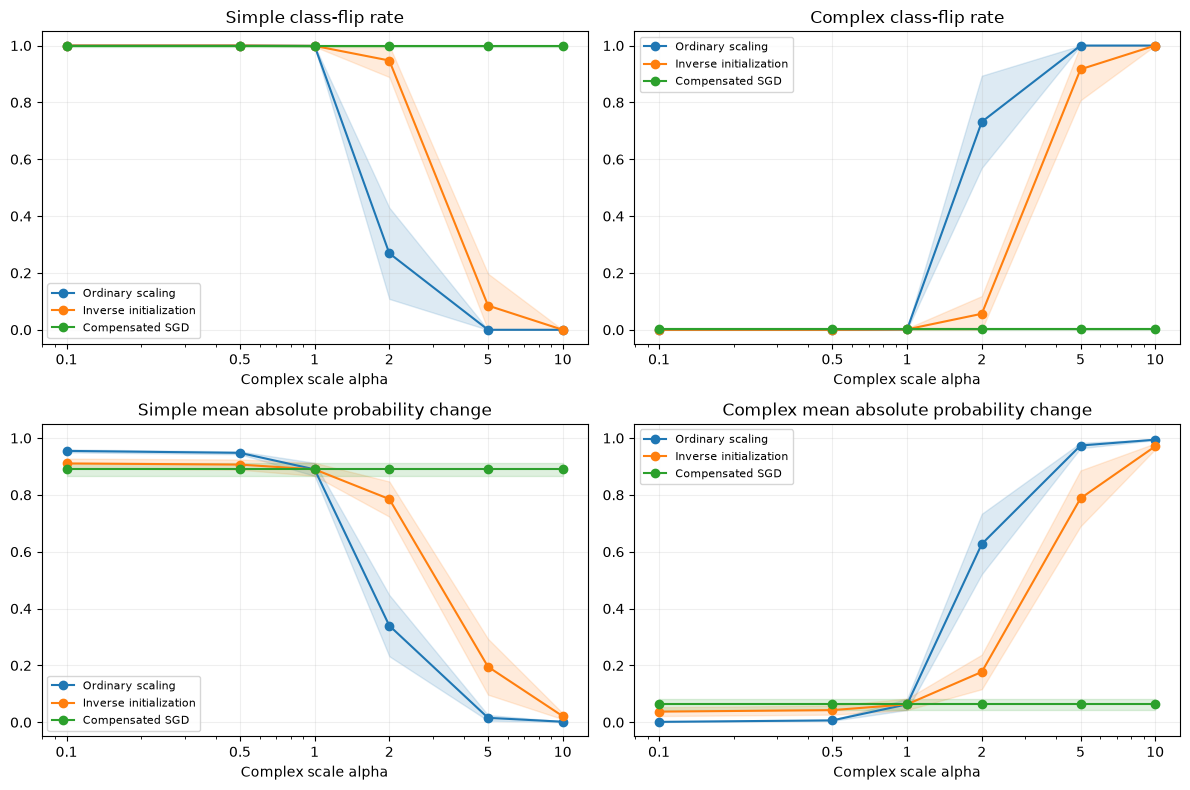

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
metrics = [('test_simple_flip_rate', 'Simple class-flip rate'),
           ('test_complex_flip_rate', 'Complex class-flip rate'),
           ('test_simple_probability_change', 'Simple mean absolute probability change'),
           ('test_complex_probability_change', 'Complex mean absolute probability change')]
for ax, (metric, title) in zip(axes.flat, metrics):
    plot_metric(ax, metric, title)
fig.tight_layout()
fig.savefig(FIGURES / 'test_counterfactuals.png', dpi=170)
plt.show()


## Compare training trajectories at one scale

These are validation and conflict curves from training, not repeated evaluations of the final test set. Check whether preference changes after accuracy becomes high. The mean curve can hide seed differences; inspect the next table too.

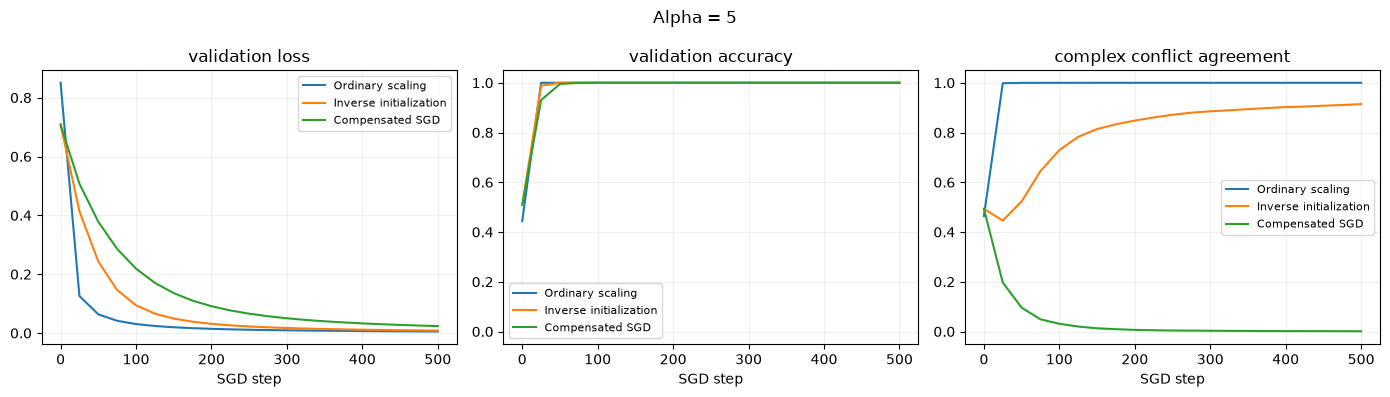

In [6]:
ALPHA_TO_VIEW = 5.0
if ALPHA_TO_VIEW not in set(history.alpha):
    ALPHA_TO_VIEW = sorted(history.alpha.unique())[-1]
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for condition in conditions:
    subset = history[(history.condition == condition) & (history.alpha == ALPHA_TO_VIEW)]
    mean = subset.groupby('step')[['validation_loss', 'validation_accuracy', 'complex_conflict_agreement']].mean()
    for ax, metric in zip(axes, mean.columns):
        ax.plot(mean.index, mean[metric], label=labels[condition], color=colors[condition])
        ax.set(title=metric.replace('_', ' '), xlabel='SGD step')
        ax.grid(alpha=0.2)
        ax.legend(fontsize=8)
axes[1].set_ylim(-0.05, 1.05)
axes[2].set_ylim(-0.05, 1.05)
fig.suptitle(f'Alpha = {ALPHA_TO_VIEW:g}')
fig.tight_layout()
fig.savefig(FIGURES / f'training_alpha_{ALPHA_TO_VIEW:g}.png', dpi=170)
plt.show()


## Seed-level behavior and reference equivalence

Compensated equivalence is designed mathematically. Small reference-logit errors verify the implementation; they do not independently prove a universal explanation of simplicity bias. Compare probability responses as well as hard decisions. A dominant rule on conflict probes need not mean complete insensitivity to the other group.

In [7]:
display(final[final.alpha == ALPHA_TO_VIEW][['condition', 'seed', 'alpha',
    'test_accuracy', 'complex_conflict_agreement',
    'test_simple_flip_rate', 'test_complex_flip_rate',
    'test_simple_probability_change', 'test_complex_probability_change']]
    .sort_values(['condition', 'seed']))
display(final.groupby('condition')[['initial_preactivation_max_error', 'initial_logit_max_error',
    'initial_gradient_scaling_max_error', 'final_test_logit_max_error_vs_alpha1']].max())
summary = final.groupby(['condition', 'alpha']).agg(
    seeds=('seed', 'nunique'), conflict_mean=('complex_conflict_agreement', 'mean'),
    conflict_sd=('complex_conflict_agreement', 'std'), test_accuracy_mean=('test_accuracy', 'mean'),
    test_loss_mean=('test_loss', 'mean')).reset_index()
summary.to_csv(RESULTS / 'aggregated_summary.csv', index=False)
print('Saved graphs and aggregate summary to', RESULTS)


,condition,seed,alpha,test_accuracy,complex_conflict_agreement,test_simple_flip_rate,test_complex_flip_rate,test_simple_probability_change,test_complex_probability_change
14,compensated_sgd,42,5.0,1.0,0.005371,0.994141,0.007812,0.865219,0.083056
32,compensated_sgd,43,5.0,1.0,0.000000,1.000000,0.000000,0.866889,0.085354
50,compensated_sgd,44,5.0,1.0,0.000000,1.000000,0.000000,0.900543,0.056714
68,compensated_sgd,45,5.0,1.0,0.000000,1.000000,0.000000,0.898889,0.049785
86,compensated_sgd,46,5.0,1.0,0.000000,1.000000,0.000000,0.917605,0.041021
13,inverse_init,42,5.0,1.0,0.979980,0.022949,0.973633,0.135976,0.845681
31,inverse_init,43,5.0,1.0,0.989258,0.010254,0.991699,0.132947,0.849382
49,inverse_init,44,5.0,1.0,0.887695,0.107910,0.891113,0.238378,0.744434
67,inverse_init,45,5.0,1.0,0.989258,0.012207,0.989746,0.120264,0.865314
85,inverse_init,46,5.0,1.0,0.725098,0.272461,0.735840,0.349223,0.634183


,initial_preactivation_max_error,initial_logit_max_error,initial_gradient_scaling_max_error,final_test_logit_max_error_vs_alpha1
condition,,,,
compensated_sgd,4.768372e-07,1.192093e-07,2.980232e-08,0.000003
inverse_init,4.768372e-07,1.192093e-07,2.980232e-08,7.303813
ordinary,NaN,NaN,NaN,9.484276


Saved graphs and aggregate summary to c:\Users\ESHAAN\HAKUR\SimpBias\continuous_xnor\results


## Questions to answer from your actual results

- Do feature-only models learn both rules on held-out inputs under the matched budget?
- Does conflict agreement change with scale, and is the change consistent across seeds?
- Does inverse initialization delay or remove that change?
- Does compensated SGD match reference logits and prediction responses?
- Do probability changes reveal sensitivity hidden by hard decisions?

Do not treat preview runs as research findings. Independent test coordinates address the four-prototype limitation within this distribution, but do not establish extrapolation outside Uniform(0.5, 1.5), equalize group dimensions, or identify unique causal reliance.